# Sex-Specific Random Survival Forest: Permutation Importance by Sex

RSF fit separately on each sex (same tuned hyperparameters as the pooled model), with permutation importance compared between female and male models. Female: 1,350 patients / 187 events. Male: 1,700 patients / 285 events.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import CoxPHFitter
from sksurv.ensemble import RandomSurvivalForest
from sksurv.util import Surv
from sksurv.metrics import concordance_index_censored
from sklearn.inspection import permutation_importance
import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 42
BASE = '../../'
USYD = ['#E64626', '#DAA8A2', '#71A399', '#8F9EC9', '#1A345E']

df = pd.read_csv(BASE + 'modeling_dataset.csv')
COMORBID_COLS = ['cat_Renal', 'cat_FluidElectrolyte', 'cat_Metabolic', 'cat_Respiratory',
                  'cat_MentalHealthSubstance', 'cat_Musculoskeletal', 'cat_Hematologic', 'cat_Hepatic',
                  'cat_Neurologic', 'cat_Oncologic', 'cat_EndocrineOther', 'cat_ConstitutionalFrailty']
UTILIZATION_COLS = ['baseline_n_diagnoses', 'baseline_n_procedures', 'baseline_n_claims',
                     'baseline_n_episodes', 'baseline_history_days']
COVARIATES = ['age'] + COMORBID_COLS + UTILIZATION_COLS  # sex excluded -- these are per-sex fits
COX_PENALIZER = 1.0  # tuned in 07_gbsa_and_cox_tuning.ipynb

surv_df = df[['years_followup', 'incident_cvd', 'age', 'sex', 'split'] + COMORBID_COLS + UTILIZATION_COLS].copy()
surv_df['incident_cvd'] = surv_df['incident_cvd'].astype(int)
for s in ['F', 'M']:
    sub = surv_df[surv_df.sex == s]
    print(f'{s}: {len(sub):,} patients, {sub.incident_cvd.sum():,} events ({100*sub.incident_cvd.mean():.1f}%)')

F: 1,350 patients, 187 events (13.9%)
M: 1,700 patients, 285 events (16.8%)


## 1. Sex-specific RSF

Same tuned hyperparameters as the pooled model, fit separately within each sex's train/test split.

In [5]:
RSF_BEST_PARAMS = dict(min_samples_leaf=10, max_features='sqrt', n_estimators=300)
rsf_importance_by_sex = {}
rsf_cindex_by_sex = {}

for s in ['F', 'M']:
    sub = surv_df[surv_df.sex == s]
    train, test = sub[sub.split == 'train'], sub[sub.split == 'test']
    X_train, X_test = train[COVARIATES], test[COVARIATES]
    y_train = Surv.from_arrays(event=train['incident_cvd'].astype(bool), time=train['years_followup'])
    y_test = Surv.from_arrays(event=test['incident_cvd'].astype(bool), time=test['years_followup'])
    print(f'{s}: train={len(train)} ({train.incident_cvd.sum()} events), test={len(test)} ({test.incident_cvd.sum()} events)')

    rsf = RandomSurvivalForest(n_jobs=-1, random_state=RANDOM_STATE, **RSF_BEST_PARAMS)
    rsf.fit(X_train, y_train)
    c_index = concordance_index_censored(y_test['event'], y_test['time'], rsf.predict(X_test))[0]
    rsf_cindex_by_sex[s] = c_index
    print(f'  test C-index: {c_index:.4f}')

    perm = permutation_importance(rsf, X_test, y_test, n_repeats=15, random_state=RANDOM_STATE, n_jobs=-1)
    rsf_importance_by_sex[s] = pd.Series(perm.importances_mean, index=COVARIATES)

imp_compare = pd.DataFrame({'importance_female': rsf_importance_by_sex['F'],
                             'importance_male': rsf_importance_by_sex['M']})
imp_compare['rank_female'] = imp_compare['importance_female'].rank(ascending=False).astype(int)
imp_compare['rank_male'] = imp_compare['importance_male'].rank(ascending=False).astype(int)
imp_compare = imp_compare.sort_values('importance_female', ascending=False)
imp_compare.to_csv('sex_specific_rsf_importance.csv')
print()
print('=== RSF permutation importance by sex ===')
print(imp_compare.round(4))

F: train=1083 (152 events), test=267 (35 events)


  test C-index: 0.7019


M: train=1357 (226 events), test=343 (59 events)


  test C-index: 0.6499



=== RSF permutation importance by sex ===
                           importance_female  importance_male  rank_female  \
age                                   0.1022           0.0414            1   
baseline_n_diagnoses                  0.0457           0.0174            2   
baseline_history_days                 0.0329           0.0207            3   
baseline_n_procedures                 0.0288           0.0271            4   
cat_Oncologic                         0.0075           0.0015            5   
cat_Musculoskeletal                   0.0020           0.0001            6   
cat_Respiratory                       0.0017           0.0001            7   
cat_FluidElectrolyte                  0.0010          -0.0006            8   
baseline_n_claims                     0.0004           0.0035            9   
cat_Hepatic                           0.0001           0.0000           10   
cat_MentalHealthSubstance             0.0000          -0.0001           13   
cat_Hematologic      

## 2. Figure: RSF importance ranking, female vs. male

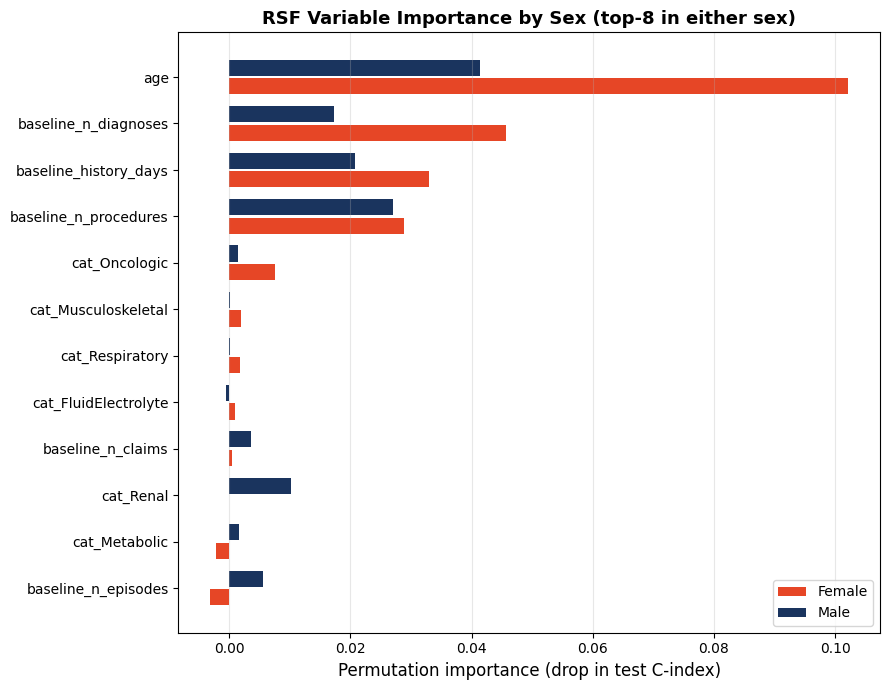

saved sex_specific_rsf_importance.png


In [6]:
top_either = imp_compare[(imp_compare.rank_female <= 8) | (imp_compare.rank_male <= 8)]
top_either = top_either.sort_values('importance_female', ascending=True)
fig, ax = plt.subplots(figsize=(9, 7))
y = np.arange(len(top_either))
ax.barh(y - 0.2, top_either['importance_female'], height=0.35, color=USYD[0], label='Female')
ax.barh(y + 0.2, top_either['importance_male'], height=0.35, color=USYD[4], label='Male')
ax.set_yticks(y)
ax.set_yticklabels(top_either.index)
ax.set_xlabel('Permutation importance (drop in test C-index)', fontsize=12)
ax.set_title('RSF Variable Importance by Sex (top-8 in either sex)', fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(alpha=0.3, axis='x')
plt.tight_layout()
plt.savefig('sex_specific_rsf_importance.png', dpi=300, bbox_inches='tight')
plt.show()
print('saved sex_specific_rsf_importance.png')